In [28]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import funcs
import astropy.io.fits as fits
from astropy.table import Table
from astropy.cosmology import WMAP9 as cosmo
import h5py
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d

path_simba = "../simba_rlf_data/df_simba.pkl"
df_simba = pd.read_pickle(path_simba)

path_manga = "../simba_rlf_data/df_manga.pkl"
df_manga = pd.read_pickle(path_manga)

path_nt = "../simba_rlf_data/df_nt.pkl"
df_nt = pd.read_pickle(path_nt)

path_simba_z014 = "../simba_rlf_data/df_simba_z014.pkl"
df_simba_z014 = pd.read_pickle(path_simba_z014)

In [37]:
def generate_mock_galaxies_baldry( log_M_star, phi1, alpha1, phi2, alpha2, num_samples):
    
    log_lower_bound = 8    
    log_upper_bound = 12
    log_M_grid = np.linspace(log_lower_bound, log_upper_bound, num_samples)

    pdf_grid = funcs.baldry_gsmf(10**log_M_grid, log_M_star, phi1, alpha1, phi2, alpha2)
    cdf_grid = cumulative_trapezoid(pdf_grid, log_M_grid, initial = 0)
    cdf_grid = cdf_grid/cdf_grid[-1]

    inverse_cdf  = interp1d(cdf_grid, log_M_grid)
    random_uniform = np.random.uniform(0,1, num_samples)

    random_log_Ms = inverse_cdf(random_uniform)

    return random_log_Ms



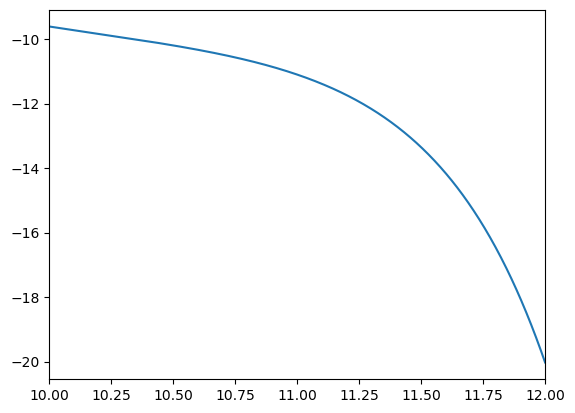

In [ ]:
log_M_star = 10.66
phi1 = 3.96e-3
alpha1 = -0.35
phi2 = 0.79e-3
alpha2 = -1.47

log_M_bins = np.linspace(10,12,1000)
pdfs = funcs.baldry_gsmf(10**log_M_bins, log_M_star, phi1,alpha1, phi2, alpha2)
log_pdfs = np.log10(pdfs)

plt.plot(log_M_bins, log_pdfs)
plt.xlim(10,12)
plt.show()